# <ins> **Projet ML-DL : Apprentissage non supervisée** <ins>
## <ins> **Membres du groupe**: <ins>
- 3822	RAZAFINDRAZAKA Fitahinasoa Lahatra Octave
- 3823	SALOHIMAMPIONONA Maminiala Toussaint
- 1446H-F	SAMARTINA Eldinha Reinitha
- 3859	RAFANOMEZANTSOA Tolojanahary Fabrice
- 3849	SOLOFOTIANA Herimanda Fanantenana
- 3817	TSIHALANDRAIBE Maharavo Angelon
- 3819	RAVAOMARIA Estella

## **Importation des librarie a utilisée**

In [90]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn import  model_selection
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import silhouette_score, accuracy_score, classification_report
import joblib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn import metrics


In [91]:
dataset = pd.read_csv ("fruits.csv", header=None, names=["x", "y"], dtype=str)
dataset

,x,y
0,43.7,38.57
1,22.47,6.41
2,26.09,8.72
3,36.18,27.45
4,18.24,1.89
...,...,...
395,41.16,41.34
396,58.76,94.25
397,26.91,9.6
398,20.36,5.5


In [92]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   x       400 non-null    str  
 1   y       400 non-null    str  
dtypes: str(2)
memory usage: 6.4 KB


<Axes: >

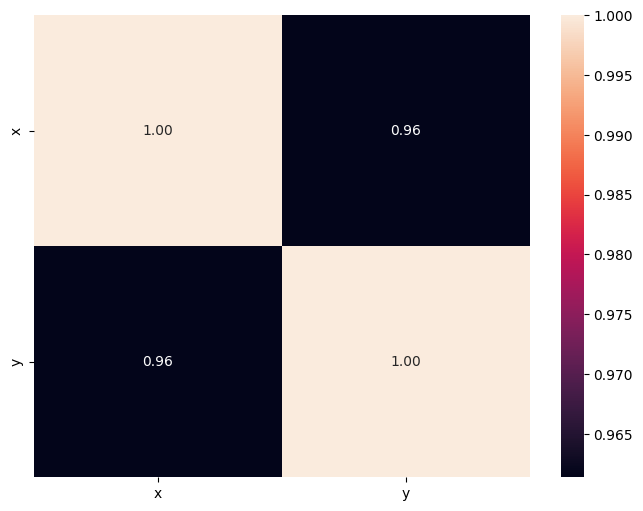

In [93]:
plt.figure (figsize=(8,6))
sns.heatmap(dataset.corr(),annot=True, fmt='0.2f')

In [94]:
X = dataset[["x", "y"]].values
train_set, test_set = model_selection.train_test_split (X,test_size= 0.3, random_state= 4712)
train_set.shape

(280, 2)

In [95]:
test_set.shape

(120, 2)

In [96]:
scaler = StandardScaler()
Xs_train = scaler.fit_transform(train_set)
Xs_test = scaler.transform(test_set)
k_min = 2
k_max = 10
inertias = []
silhouettes = []
Ks = list(range(k_min, k_max + 1))

In [97]:
for k in Ks:
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(Xs_train)
    inertias.append(model.inertia_)
        
    if k > 1:
        silhouettes.append(silhouette_score(Xs_train, labels))
    else:
        silhouettes.append(np.nan)

Text(0.5, 1.0, 'Silhouette')

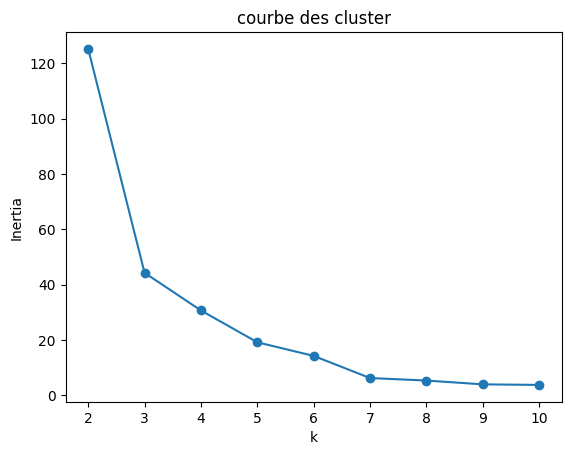

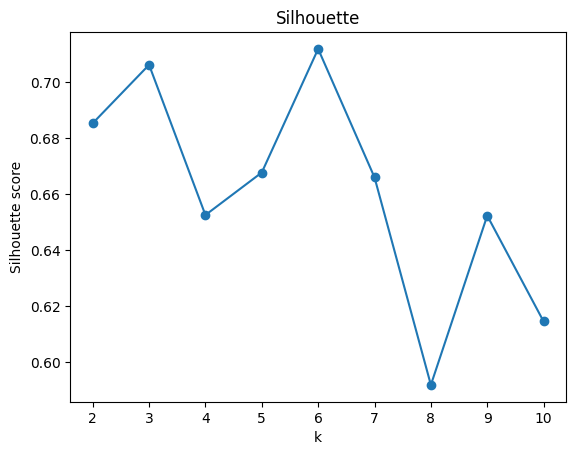

In [98]:
plt.figure()
plt.plot(Ks, inertias, marker="o")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.title("courbe des cluster")
plt.figure()
plt.plot(Ks, silhouettes, marker="o")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.title("Silhouette")

In [99]:
best_idx = int(np.nanargmax(silhouettes))
best_k = Ks[best_idx]
best_k

6

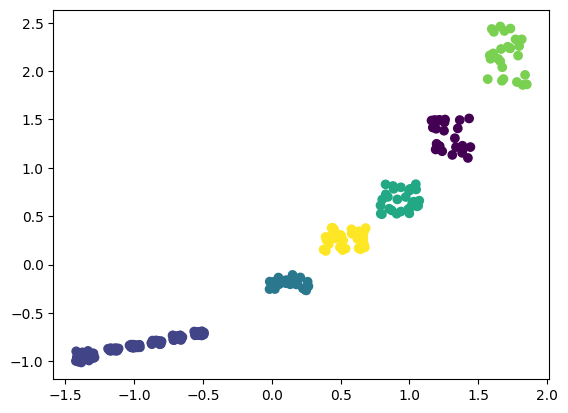

In [100]:
model_k = KMeans (n_clusters=best_k, random_state= 42)
predict_train = model_k.fit_predict(Xs_train)
plt.scatter(Xs_train[:,0], Xs_train[:,1], c=predict_train)

In [101]:
predict_test =  model_k.fit_predict(Xs_test)

In [102]:
rf = RandomForestClassifier(random_state= 42 , n_estimators=100)
rf.fit(Xs_train, predict_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [103]:
rf_preds_train = rf.predict (Xs_train)
cls_report1 = classification_report (predict_train,rf_preds_train)
print (cls_report1)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        26
           1       1.00      1.00      1.00       140
           2       1.00      1.00      1.00        24
           3       1.00      1.00      1.00        29
           4       1.00      1.00      1.00        26
           5       1.00      1.00      1.00        35

    accuracy                           1.00       280
   macro avg       1.00      1.00      1.00       280
weighted avg       1.00      1.00      1.00       280



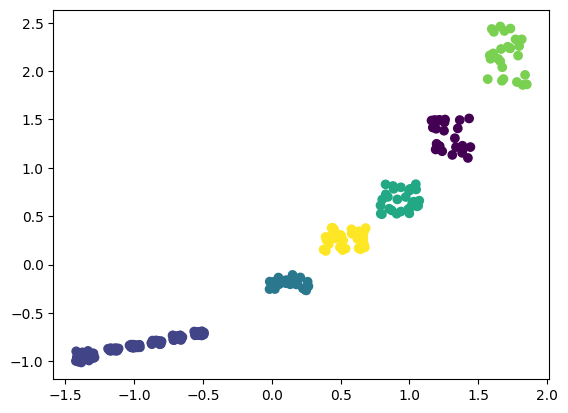

In [104]:
plt.scatter(Xs_train[:,0], Xs_train[:,1], c=rf_preds_train)

In [105]:
rf_preds = rf.predict(Xs_test)
acc = accuracy_score(predict_test, rf_preds)
cls_report = classification_report(predict_test, rf_preds)
print (cls_report)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        12
           1       1.00      1.00      1.00        60
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        13
           4       1.00      1.00      1.00        10
           5       0.00      0.00      0.00        13

    accuracy                           0.58       120
   macro avg       0.33      0.33      0.33       120
weighted avg       0.58      0.58      0.58       120



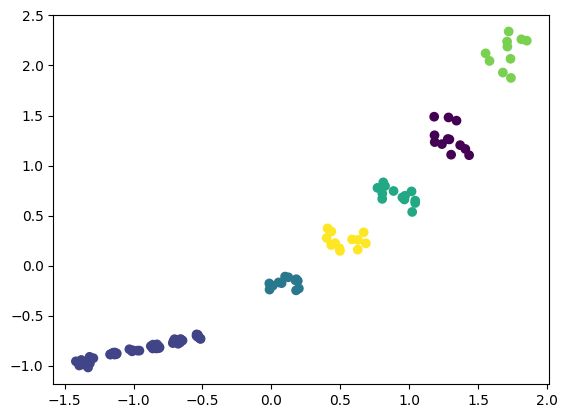

In [106]:
plt.scatter(Xs_test[:,0], Xs_test[:,1], c=rf_preds)

In [107]:
artefact = {"kmeans": model_k, "rf": rf, "scaler": scaler}
joblib.dump(artefact, "./model/model.joblib")

['./model/model.joblib']